# Iris Flower Classification

## 1. Import Libraries


In [2]:
print("Welcome to Datheon Machine Learning Task 1!")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("All libraries imported successfully!")

Welcome to Datheon Machine Learning Task 1!
All libraries imported successfully!


## 2. Dataset Loading

In [3]:
# Load Iris Dataset

from sklearn.datasets import load_iris

# Load the dataset
iris = load_iris()

# Convert dataset into DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df['species'] = iris.target

# Display first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 3. Data Exploration


In [4]:
# Check dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()


Dataset Shape: (150, 5)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [5]:
# Check the distribution of flower species

print(df['species'].value_counts())

species
0    50
1    50
2    50
Name: count, dtype: int64


In [6]:
df['species_name'] = df['species'].map({
    0: 'Setosa',
    1: 'Versicolor',
    2: 'Virginica'
})
# Display first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,Setosa
1,4.9,3.0,1.4,0.2,0,Setosa
2,4.7,3.2,1.3,0.2,0,Setosa
3,4.6,3.1,1.5,0.2,0,Setosa
4,5.0,3.6,1.4,0.2,0,Setosa


## 5. Data Preprocessing

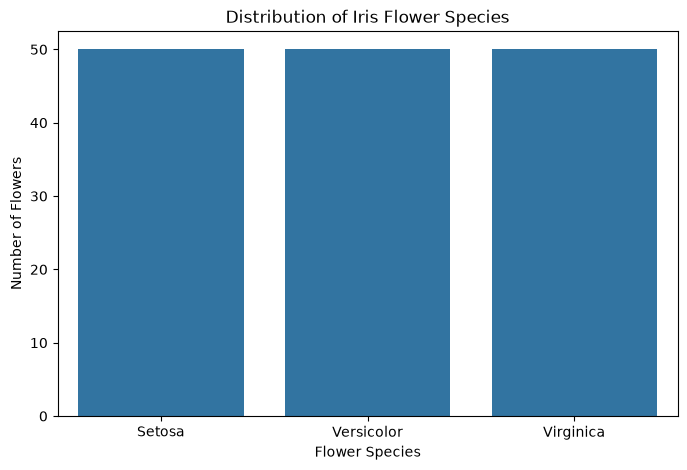

In [7]:
# Visualize the distribution of Iris species

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='species_name')

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Flowers")

plt.show()

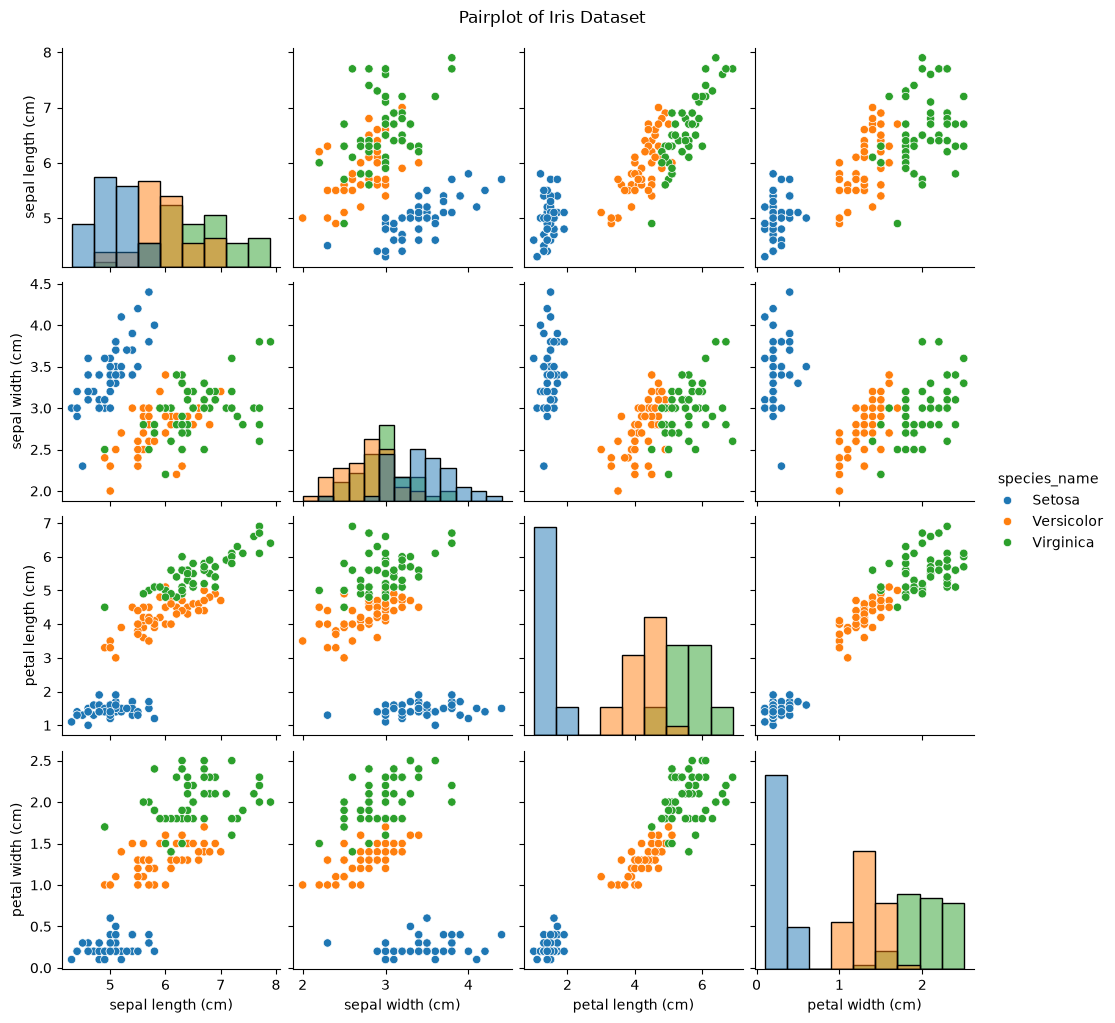

In [8]:
# Pairplot visualization

sns.pairplot(
    df,
    vars=iris.feature_names,
    hue='species_name',
    diag_kind='hist'
)

plt.suptitle("Pairplot of Iris Dataset", y=1.02)

plt.show()

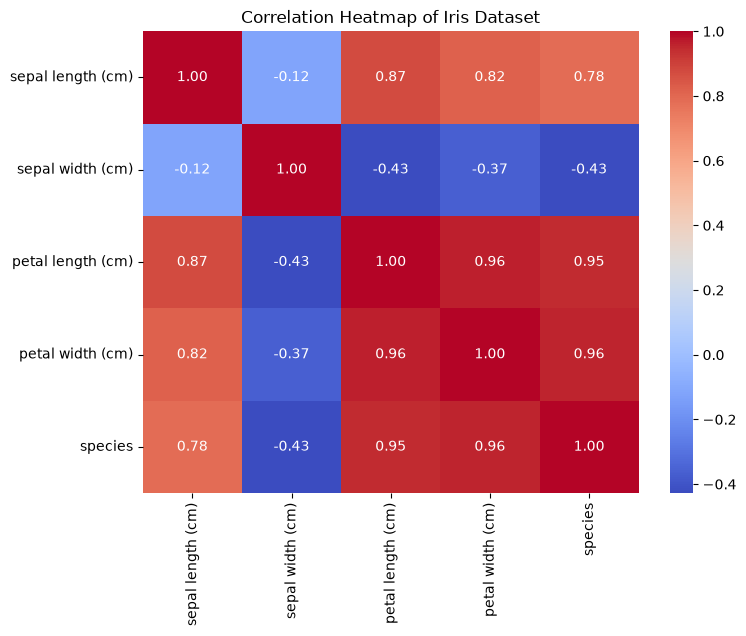

In [9]:
# Select only numerical columns
numerical_df = df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Iris Dataset")

plt.show()

In [10]:
# Separate Features and Target

X = df[iris.feature_names]

y = df['species']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (150, 4)
Target Shape: (150,)


In [11]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display shapes

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [12]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150, 4)
y shape: (150,)


In [13]:
# Import StandardScaler

from sklearn.preprocessing import StandardScaler

# Create scaler object

scaler = StandardScaler()

# Fit and transform training data

X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Testing Data:")
print(X_test_scaled[:5])

Scaled Training Data:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]

Scaled Testing Data:
[[-1.72156775 -0.10821272 -1.40250384 -1.32327558]
 [ 0.30848902 -0.10821272  0.64163131  0.78343181]
 [-1.12449223 -1.45154306 -0.2668732  -0.26992188]
 [-1.00507713 -1.67543145 -0.2668732  -0.26992188]
 [-1.72156775  0.33956406 -1.40250384 -1.32327558]]


## 6. Logistic Regression

In [14]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model

lr_model = LogisticRegression(max_iter=200)

# Train the model

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [15]:
# Predict using Logistic Regression

y_pred_lr = lr_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred_lr)

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [16]:
# Calculate model accuracy

from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


## 7. Decision Tree Classifier

In [17]:
# Import Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model

dt_model = DecisionTreeClassifier(random_state=42)

# Train the model

dt_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [18]:
# Predict using Decision Tree

y_pred_dt = dt_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred_dt)

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [19]:
# Calculate Decision Tree accuracy

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


In [20]:
# Compare model accuracies

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %
Decision Tree Accuracy: 93.33333333333333 %


In [21]:
from sklearn.metrics import classification_report

In [22]:
print("LOGISTIC REGRESSION REPORT")

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=iris.target_names
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [23]:
print("DECISION TREE REPORT")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=iris.target_names
))

DECISION TREE REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



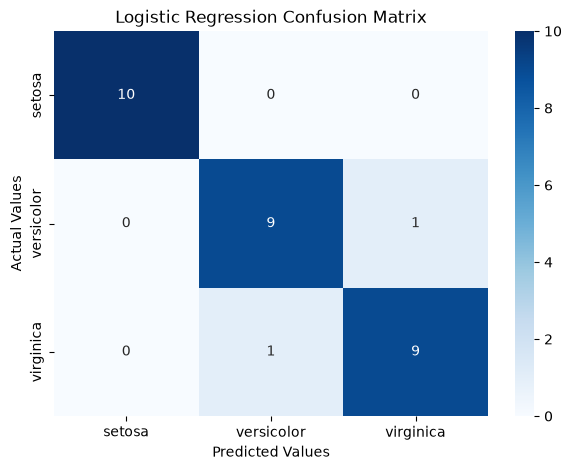

In [24]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

## 8. Model Evaluation

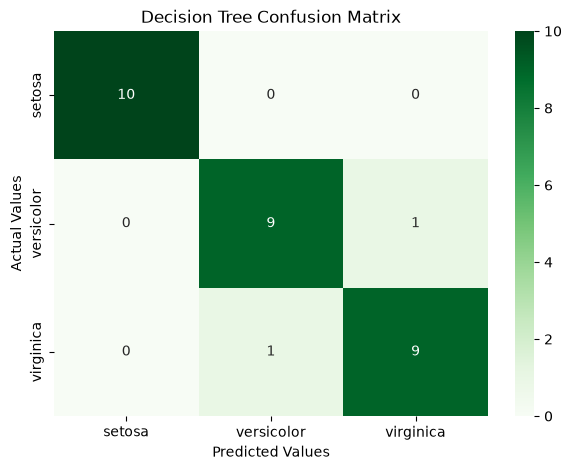

In [25]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [26]:
print("LOGISTIC REGRESSION REPORT")

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=iris.target_names
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [27]:
print("DECISION TREE REPORT")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=iris.target_names
))

DECISION TREE REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 9. Model Comparison

In [28]:
# Compare both Machine Learning models

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [lr_accuracy, dt_accuracy]
})

print(comparison)

                 Model  Accuracy
0  Logistic Regression  0.933333
1        Decision Tree  0.933333


In [29]:
# Final Model Comparison

lr_report = classification_report(
    y_test, y_pred_lr, output_dict=True
)

dt_report = classification_report(
    y_test, y_pred_dt, output_dict=True
)

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [lr_report['accuracy'], dt_report['accuracy']],
    'Precision': [
        lr_report['macro avg']['precision'],
        dt_report['macro avg']['precision']
    ],
    'Recall': [
        lr_report['macro avg']['recall'],
        dt_report['macro avg']['recall']
    ],
    'F1-Score': [
        lr_report['macro avg']['f1-score'],
        dt_report['macro avg']['f1-score']
    ]
})

print(comparison.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.933      0.933   0.933     0.933
1        Decision Tree     0.933      0.933   0.933     0.933


## 10. Decision Boundary Visualization

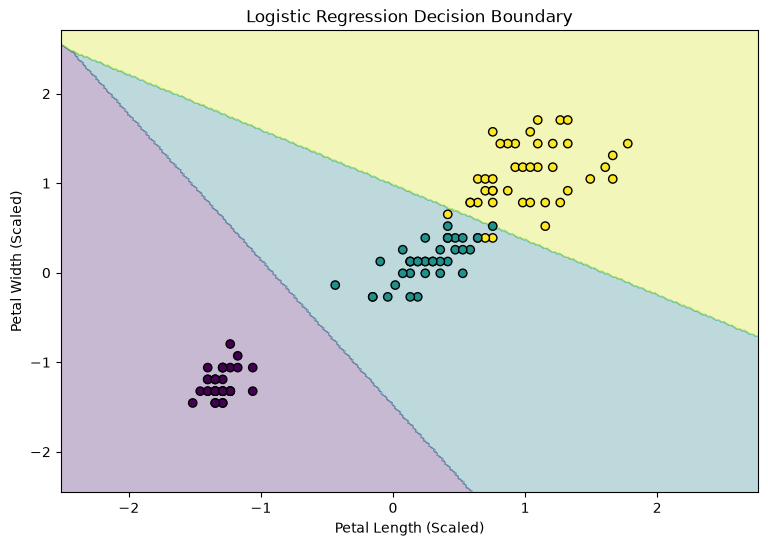

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# Select two features: Petal Length and Petal Width
X_2d = X[['petal length (cm)', 'petal width (cm)']]

# Split the dataset
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale the features
scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

# Train Logistic Regression
lr_2d = LogisticRegression(max_iter=200)

lr_2d.fit(X_train_2d_scaled, y_train_2d)

# Create mesh grid
x_min, x_max = X_train_2d_scaled[:, 0].min() - 1, X_train_2d_scaled[:, 0].max() + 1
y_min, y_max = X_train_2d_scaled[:, 1].min() - 1, X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict regions
Z = lr_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=y_train_2d,
    cmap='viridis',
    edgecolors='black'
)

plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Petal Length (Scaled)")
plt.ylabel("Petal Width (Scaled)")

plt.show()

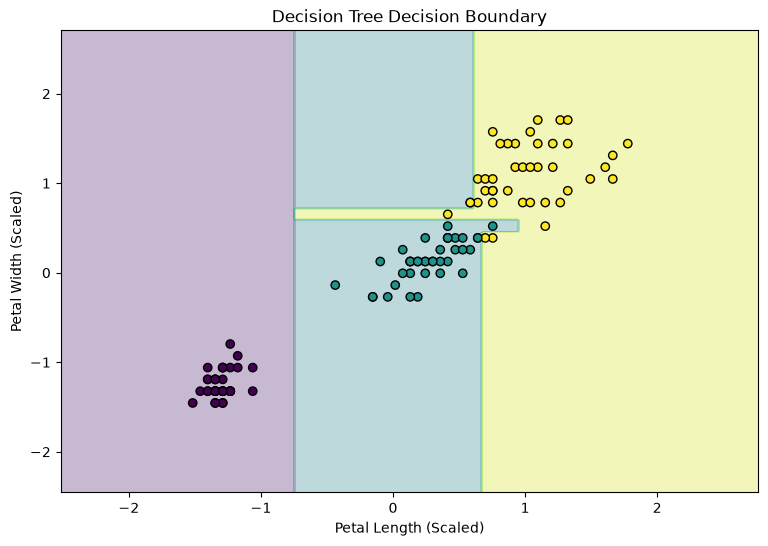

In [31]:
# Train Decision Tree using two features

dt_2d = DecisionTreeClassifier(random_state=42)

dt_2d.fit(X_train_2d_scaled, y_train_2d)

# Predict regions
Z_dt = dt_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_dt = Z_dt.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z_dt, alpha=0.3, cmap='viridis')

plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=y_train_2d,
    cmap='viridis',
    edgecolors='black'
)

plt.title("Decision Tree Decision Boundary")
plt.xlabel("Petal Length (Scaled)")
plt.ylabel("Petal Width (Scaled)")

plt.show()

## 11. Conclusion

## 🏆 Project Conclusion

In this project, I successfully implemented a complete machine learning classification workflow using the Iris dataset as part of the Datheon Machine Learning and Data Science Internship.

The project involved data loading, data exploration, data preprocessing, exploratory data analysis (EDA), feature scaling, model development, and performance evaluation.

Two supervised machine learning algorithms were implemented:

- **Logistic Regression**
- **Decision Tree Classifier**

Both models achieved an accuracy of **93.33%** on the testing dataset, demonstrating their ability to classify Iris flower species effectively.

Through this project, I gained practical experience in Python programming, data visualization, feature preprocessing, supervised machine learning, model evaluation, and comparing classification algorithms.

Overall, this project strengthened my understanding of the end-to-end machine learning process and provided valuable hands-on experience in solving a real-world classification problem.

**Key Takeaway:** Both classification algorithms performed equally in terms of test accuracy, highlighting the importance of evaluating machine learning models using multiple performance metrics rather than accuracy alone.

---